# Fig. 6b: global sorting accuracy across simulations

**author**: laquitainesteeve@gmail.com

**purpose**: proportion of ground truth neurons sorted with above 80% accuracy by each spike sorter, for Neuropixels (S: Buccino synthetic, NS: biophysical spontaneous, E: biophysical evoked at 40 kHz) and pooled over the three depths of the dense probe (D1-3). Source data and svg are saved in figures/8_source_data/fig6b/.

**method**
* first 10 minutes; ground truth neurons are within 50 microns of the contacts
* a ground truth neuron's accuracy is its best agreement score (delta_time = 1.3 ms) with a sorted unit; the sorted units are the "good" units for the Kilosort family and all units for Kilosort and Herdingspikes
* chi-square goodness-of-fit test: do the sorters have the same accuracy?

**data**: NS and dense probes D2-3 are downloaded with 0_download_sortings.ipynb / 0_download_ground_truths.ipynb. S (Buccino) and E (40 kHz) sortings were copied from the sorting campaign folders into dataset/01_intermediate/sorting/buccino and npx_evoked_40khz (ground truth: dataset/00_raw/ground_truth_npx_evoked_40khz_10m).

* D1 sortings: the DANDI sortings of dense depth 1 (sub-003-fitted, KS3 to HS) are identical to those of depth 2 (sub-004-fitted), so they were replaced with the depth-1 sortings from the sorting campaign (dataset/01_intermediate/sorting/dense_probe1).

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)

# custom package
from src.nodes.analysis.accuracy import accuracy as acc

# PARAMETERS
DT = 1.3          # ms (optimized)
THR = 0.8         # "good" unit threshold
SORTERS = ["ks4", "ks3", "ks2.5", "ks2", "ks", "hs"]

# DATASETS: ground truth and sortings (KS4, KS3, KS2.5, KS2, KS, HS)
SORTING = "dataset/01_intermediate/sorting/"
RAW = "dataset/00_raw/"
def sortings(folder):
    return [f"{SORTING}{folder}/Sorting{s}_10m" for s in ["KS4", "KS3", "KS2_5", "KS2", "KS", "HS"]]

DATASETS = {
    # Neuropixels
    "S":  dict(probe="Neuropixels", gt=RAW + "sorting_buccino", sorting=sortings("buccino")),
    "NS": dict(probe="Neuropixels", gt=RAW + "ground_truth_npx_spont", sorting=sortings("npx_spont")),
    "E":  dict(probe="Neuropixels", gt=RAW + "ground_truth_npx_evoked_40khz_10m", sorting=sortings("npx_evoked_40khz")),
    # dense probe (3 depths)
    "D1": dict(probe="dense", gt=RAW + "ground_truth_dense_probe1", sorting=sortings("dense_probe1")),
    "D2": dict(probe="dense", gt=RAW + "ground_truth_dense_probe2", sorting=sortings("dense_probe2")),
    "D3": dict(probe="dense", gt=RAW + "ground_truth_dense_probe3", sorting=sortings("dense_probe3")),
}

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

## Calculate the accuracy of each ground truth neuron

In [2]:
%%time

# accuracy[dataset]: sorters (rows) x ground truth neurons (columns), best agreement score
accuracy = {}
for name, d in DATASETS.items():
    accuracy[name] = acc.get_accuracy(*d["sorting"], d["gt"], DT)
    print(name, "ground truth neurons:", accuracy[name].shape[1])

S ground truth neurons: 250


NS ground truth neurons: 1388


E ground truth neurons: 1552


D1 ground truth neurons: 287


D2 ground truth neurons: 770


D3 ground truth neurons: 1123
CPU times: user 11.8 s, sys: 217 ms, total: 12 s
Wall time: 11.9 s


## Source data: number of well-sorted ground truth neurons per sorter and dataset

In [3]:
rows = []
for name, d in DATASETS.items():
    for ix, sorter in enumerate(SORTERS):
        rows.append({
            "probe": d["probe"],
            "dataset": name,
            "sorter": sorter,
            "n_well_sorted": int((accuracy[name][ix, :] >= THR).sum()),
            "n_ground_truth": int(accuracy[name].shape[1]),
        })
df = pd.DataFrame(rows)
display(df)

,probe,dataset,sorter,n_well_sorted,n_ground_truth
0,Neuropixels,S,ks4,224,250
1,Neuropixels,S,ks3,214,250
2,Neuropixels,S,ks2.5,244,250
3,Neuropixels,S,ks2,247,250
4,Neuropixels,S,ks,187,250
5,Neuropixels,S,hs,124,250
6,Neuropixels,NS,ks4,79,1388
7,Neuropixels,NS,ks3,56,1388
8,Neuropixels,NS,ks2.5,190,1388
9,Neuropixels,NS,ks2,198,1388


In [4]:
def plot_source_data(df: pd.DataFrame):
    """Total sorting accuracy across ground truths, per probe and sorter, with the chi-square p-value"""

    fig, ax = plt.subplots(1, 2, figsize=(3.4, 2.2))
    plt.subplots_adjust(left=0.2, right=0.99, top=0.56, bottom=0.25, wspace=0.35)
    heads = {"Neuropixels": "Neuropixels (NPX)", "dense": "Dense probe"}
    for a, probe in zip(ax, ["Neuropixels", "dense"]):

        # total number of well-sorted neurons per sorter across the probe's ground truths
        d = df[df["probe"] == probe]
        good = d.groupby("sorter", sort=False)["n_well_sorted"].sum().loc[SORTERS].values
        total = d[d["sorter"] == SORTERS[0]]["n_ground_truth"].sum()
        accuracy_total = good / total
        p_value = stats.chisquare(f_obs=good / total * 100, ddof=0).pvalue

        # plot
        a.bar(SORTERS, accuracy_total, color=COLORS[: len(SORTERS)], width=0.8)
        a.set_ylim([0, 0.22]); a.set_yticks([0, 0.1, 0.2])
        a.set_xlabel("Spike sorters", labelpad=3)
        a.tick_params(axis="x", labelrotation=45)

        # disconnect axes (R style)
        a.spines[["right", "top"]].set_visible(False)
        a.spines["bottom"].set_position(("axes", -0.05))
        a.spines["left"].set_position(("axes", -0.05))

        # add unit counts
        for ix in range(len(SORTERS)):
            a.annotate(f"{good[ix]}", (ix, accuracy_total[ix] + 0.006), ha="center", va="bottom", color="k")

        # statistics: chi-square goodness-of-fit across sorters (bar spanning the sorters)
        a.plot([-0.4, len(SORTERS) - 0.6], [0.235, 0.235], "k-", linewidth=0.5, clip_on=False)
        a.text((len(SORTERS) - 1) / 2, 0.24, f"p={p_value:.1f}", ha="center", va="bottom", clip_on=False)

        # titles
        a.text(0.5, 1.5, heads[probe], transform=a.transAxes, ha="center", va="bottom", fontweight="bold", fontsize=6.5)
        a.text(0.5, 1.38, f"(n={total:,} model neurons)", transform=a.transAxes, ha="center", va="bottom", fontsize=5.5)
    ax[0].set_ylabel("Proportion of neurons\nsorted with above 80% accuracy")
    fig.text(0.6, 0.98, "Global accuracy across simulations", ha="center", va="top", fontweight="bold", fontsize=6.5)
    return fig, ax

## Plot and save the figure and the source data

CPU times: user 119 ms, sys: 2.01 ms, total: 121 ms
Wall time: 121 ms


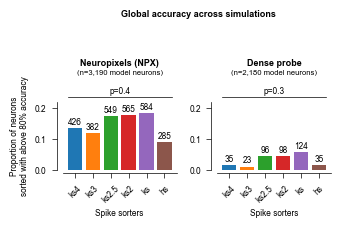

In [5]:
%%time

# plot
fig, ax = plot_source_data(df)

# save figure
os.makedirs("figures/8_source_data/fig6b", exist_ok=True)
plt.savefig("figures/8_source_data/fig6b/fig6b.svg", bbox_inches="tight", **savefig_cfg)

# save source data
df.to_excel("figures/8_source_data/fig6b/fig6b.xlsx", index=False)

## Check: replot from the saved source data

CPU times: user 21.8 ms, sys: 0 ns, total: 21.8 ms
Wall time: 21.8 ms


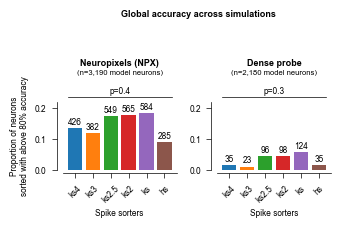

In [6]:
%%time

df = pd.read_excel("figures/8_source_data/fig6b/fig6b.xlsx")
fig, ax = plot_source_data(df)

## Hypothesis testing: spike sorters have the same accuracy (chi-square goodness-of-fit)

In [7]:
# frequencies (percent) of well-sorted neurons per sorter, as expected by scipy.stats.chisquare
for probe in ["Neuropixels", "dense"]:
    d = df[df["probe"] == probe]
    good = d.groupby("sorter", sort=False)["n_well_sorted"].sum().loc[SORTERS].values
    total = d[d["sorter"] == SORTERS[0]]["n_ground_truth"].sum()
    result = stats.chisquare(f_obs=good / total * 100, ddof=0)
    dof = len(good) - 1
    print(f"{probe}: expected accuracy {np.mean(good / total * 100):.0f}%; chi2({dof}, N={total}) = {result.statistic:.1f}, p = {result.pvalue:.2f}")

Neuropixels: expected accuracy 15%; chi2(5, N=3190) = 4.9, p = 0.43
dense: expected accuracy 3%; chi2(5, N=2180) = 6.0, p = 0.30
